# Project 1 — Linear Regression and Regularization

Machine Learning in Finance & Insurance — ETH Zurich, Fall 2026

**Group members:** Paul Vidal, Victor Denner, Jules Roux, Thibaut Doulat, Célian Dalla-Vale

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd 
import scipy.stats as stats
import statsmodels.api as sm

from sklearn.compose import ColumnTransformer
from sklearn.decomposition import TruncatedSVD
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

## Question 1

### 1.a — Import the data and separate $X$ and $y$

In [2]:
housing = pd.read_csv(
    "Housing.csv",
    keep_default_na=False
)

# categorical variables where "NA" is a real category (e.g. "no garage"), see data_description.txt
valid_na_columns = ["Alley", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
                    "FireplaceQu", "GarageType", "GarageFinish", "GarageQual", "GarageCond",
                    "PoolQC", "Fence", "MiscFeature"]

# everywhere else, "NA" means missing ("None" is a real category of MasVnrType, so it is kept)
for column in housing.columns:
    if column not in valid_na_columns:
        housing[column] = housing[column].replace("NA", np.nan)

numeric_features = [
    "LotFrontage", "LotArea", "OverallQual", "OverallCond", "YearBuilt",
    "YearRemodAdd", "MasVnrArea", "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF",
    "TotalBsmtSF", "1stFlrSF", "2ndFlrSF", "LowQualFinSF", "GrLivArea",
    "BsmtFullBath", "BsmtHalfBath", "FullBath", "HalfBath", "BedroomAbvGr",
    "KitchenAbvGr", "TotRmsAbvGrd", "Fireplaces", "GarageYrBlt", "GarageCars",
    "GarageArea", "WoodDeckSF", "OpenPorchSF", "EnclosedPorch", "3SsnPorch",
    "ScreenPorch", "PoolArea", "MiscVal", "MoSold", "YrSold"
]
for column in numeric_features:
    housing[column] = pd.to_numeric(housing[column])

X = housing.drop(columns=["Id", "SalePrice"])
y_original = housing["SalePrice"].astype(float)
categorical_features = [column for column in X.columns if column not in numeric_features]
X["MSSubClass"] = X["MSSubClass"].astype(str)   # dwelling-type code: categorical, not numerical

print("Dataset shape:", housing.shape)
print("Numerical predictors:", len(numeric_features))
print("Categorical predictors:", len(categorical_features))

Dataset shape: (1460, 81)
Numerical predictors: 35
Categorical predictors: 44


**Answer.** The dataset contains 1,460 houses. After removing `Id` (an identifier, not a predictor) and separating `SalePrice`, there are 79 predictors: 35 numerical and 44 categorical. `MSSubClass` is stored as a number but is categorical (dwelling type code), so it is treated as a category. `NA` is kept as a real category in the 14 variables where it means "no such feature" (e.g. no garage), and `"None"` is kept as a real category of `MasVnrType`.

### 1.b — Distribution of `SalePrice` and target transformation

Skewness before transformation: 1.880940746034036
Skewness after transformation: 0.1212103673013655


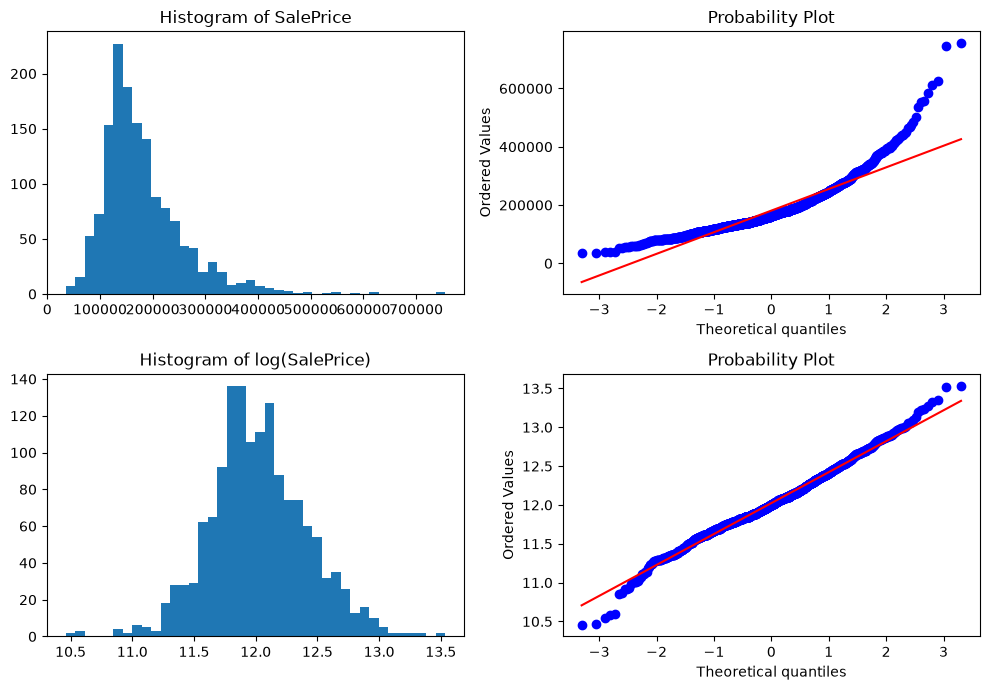

In [3]:
y = np.log(y_original)

print("Skewness before transformation:", stats.skew(y_original))
print("Skewness after transformation:", stats.skew(y))

fig, ax = plt.subplots(2, 2, figsize=(10, 7))
ax[0, 0].hist(y_original, bins=40)
ax[0, 0].set_title("Histogram of SalePrice")
ax[0, 1] = stats.probplot(y_original, plot=ax[0, 1])
ax[1, 0].hist(y, bins=40)
ax[1, 0].set_title("Histogram of log(SalePrice)")
ax[1, 1] = stats.probplot(y, plot=ax[1, 1])
plt.tight_layout()
plt.show()

**Answer.** The distribution of $SalePrice$ is strongly right-skewed. This is also visible in the Q-Q plot: the upper quantiles bend strongly upward instead of following the Gaussian reference line. This exponential-like shape suggests a long right tail.

We therefore apply the transformation

$$
Y = \log(SalePrice).
$$

The logarithm compresses large values more strongly than small values, which reduces the influence of very expensive houses and makes the distribution more symmetric.

This transformation also applies directly to the quantiles used in the Q-Q plot. Let $q_p(X)$ denote the $p$-quantile of $X$. By definition,

$$
P(X \leq q_p(X)) = p.
$$

Since the logarithm is strictly increasing,

$$
X \leq q_p(X)
\iff
\log(X) \leq \log(q_p(X)).
$$

Therefore,

$$
P(\log(X) \leq \log(q_p(X))) = p,
$$

which implies

$$
\boxed{q_p(\log X) = \log(q_p(X))}.
$$

Thus, the logarithmic transformation compresses the large upper quantiles responsible for the right tail. After the transformation, the Q-Q plot is much closer to a straight line and the skewness is substantially reduced, indicating that $\log(SalePrice)$ is closer to a Gaussian distribution. Considering such transformations is important because they can make the relationship between the predictors and the target more linear, reduce the influence of extreme observations, and stabilize the variance of the errors. This can make the assumptions underlying linear regression more reasonable and may improve both prediction accuracy and statistical inference.

### 1.c — 70/30 train/test split

In [4]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

y_train_original = np.exp(y_train)
y_test_original = np.exp(y_test)

print("Training shape:", X_train_raw.shape)
print("Test shape:", X_test_raw.shape)

Training shape: (1022, 79)
Test shape: (438, 79)


**Answer.** 1,022 training and 438 test observations (70/30). `X_train_raw` and `X_test_raw` are kept unprocessed for Question 3.b.

### 1.d — Missing values, standardization and one-hot encoding

In [5]:
X_train = X_train_raw.copy()
X_test = X_test_raw.copy()

# imputation with training statistics
train_means = X_train[numeric_features].mean()
X_train[numeric_features] = X_train[numeric_features].fillna(train_means)
X_test[numeric_features] = X_test[numeric_features].fillna(train_means)

for column in categorical_features:
    mode = X_train[column].mode().iloc[0]
    X_train[column] = X_train[column].fillna(mode)
    X_test[column] = X_test[column].fillna(mode)

# z-score with training mean and std
train_means = X_train[numeric_features].mean()
train_stds = X_train[numeric_features].std(ddof=0)
X_train[numeric_features] = (X_train[numeric_features] - train_means) / train_stds
X_test[numeric_features] = (X_test[numeric_features] - train_means) / train_stds

# one-hot encoding, test columns aligned with the training columns
X_train = pd.get_dummies(X_train, columns=categorical_features, dtype=float)
X_test = pd.get_dummies(X_test, columns=categorical_features, dtype=float)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Prepared training shape:", X_train.shape)
print("Prepared test shape:", X_test.shape)
print("Same columns:", X_train.columns.equals(X_test.columns))
print("Missing values in train / test:", X_train.isna().sum().sum(), X_test.isna().sum().sum())

Prepared training shape: (1022, 311)
Prepared test shape: (438, 311)
Same columns: True
Missing values in train / test: 0 0


**Answer.** Missing numerical values are imputed using the corresponding training-set mean, while missing categorical values are imputed using the most frequent training-set category. All imputation and standardization quantities are computed on the training set only and then applied to the test set.

After one-hot encoding, there are **311 columns**. The test set is aligned with the training set so that both have the same columns in the same order, and no missing values remain.

## Question 2

### 2.a — OLS with the 35 numerical features

In [6]:
X_train_num = X_train[numeric_features]
X_test_num = X_test[numeric_features]

ols_num = LinearRegression()
ols_num.fit(X_train_num, y_train)

pd.DataFrame({"Feature": ["Intercept"] + numeric_features,
              "Coefficient": np.r_[ols_num.intercept_, ols_num.coef_]})

,Feature,Coefficient
0,Intercept,12.028893
1,LotFrontage,-0.001184
2,LotArea,0.021449
3,OverallQual,0.114283
4,OverallCond,0.047926
5,YearBuilt,0.091382
6,YearRemodAdd,0.027551
7,MasVnrArea,-0.006479
8,BsmtFinSF1,0.009722
9,BsmtFinSF2,0.001543


In [7]:
pred_train_num = ols_num.predict(X_train_num)
pred_test_num = ols_num.predict(X_test_num)

q2_train_mse_log = mean_squared_error(y_train, pred_train_num)
q2_test_mse_log = mean_squared_error(y_test, pred_test_num)
q2_train_r2_log = r2_score(y_train, pred_train_num)
q2_test_r2_log = r2_score(y_test, pred_test_num)

q2_train_mse_original = mean_squared_error(y_train_original, np.exp(pred_train_num))
q2_test_mse_original = mean_squared_error(y_test_original, np.exp(pred_test_num))
q2_train_r2_original = r2_score(y_train_original, np.exp(pred_train_num))
q2_test_r2_original = r2_score(y_test_original, np.exp(pred_test_num))

pd.DataFrame([
    ["Log", "Train", q2_train_mse_log, q2_train_r2_log],
    ["Log", "Test", q2_test_mse_log, q2_test_r2_log],
    ["Original", "Train", q2_train_mse_original, q2_train_r2_original],
    ["Original", "Test", q2_test_mse_original, q2_test_r2_original]
], columns=["Scale", "Sample", "MSE", "R2"])

,Scale,Sample,MSE,R2
0,Log,Train,2.199564e-02,0.858098
1,Log,Test,2.186977e-02,0.871086
2,Original,Train,1.433794e+09,0.761772
3,Original,Test,8.291143e+08,0.881183


In [8]:
# which training houses dominate the original-scale training error?
price_pred_train_num = np.exp(pd.Series(pred_train_num, index=y_train.index))
squared_errors = (y_train_original - price_pred_train_num) ** 2
largest = squared_errors.nlargest(5).index

print("Train R2 on the original scale without the two largest errors:",
      r2_score(y_train_original.drop(largest[:2]), price_pred_train_num.drop(largest[:2])))
pd.DataFrame({"Id": housing.loc[largest, "Id"],
              "GrLivArea": housing.loc[largest, "GrLivArea"],
              "SaleCondition": housing.loc[largest, "SaleCondition"],
              "SalePrice": y_train_original.loc[largest].round(),
              "Predicted price": price_pred_train_num.loc[largest].round(),
              "Share of train SSE": squared_errors.loc[largest] / squared_errors.sum()})

Train R2 on the original scale without the two largest errors: 0.8782068884272755


,Id,GrLivArea,SaleCondition,SalePrice,Predicted price,Share of train SSE
1298,1299,5642,Partial,160000.0,854434.0,0.329098
523,524,4676,Partial,184750.0,668493.0,0.159695
1182,1183,4476,Abnorml,745000.0,449571.0,0.059562
803,804,2822,Partial,582933.0,402832.0,0.022136
178,179,2234,Partial,501837.0,356186.0,0.014477


**Answer.** On the log-price scale, the train and test results are very similar:

| Sample | MSE | $R^2$ |
|---|---:|---:|
| Train | 0.0220 | 0.858 |
| Test | 0.0219 | 0.871 |

The small train-test performance gap suggests little evidence of overfitting and indicates that the model generalizes reasonably well to unseen observations.

After inverse-transforming the predictions, the results on the original SalePrice scale are:

| Sample | MSE | $R^2$ |
|---|---:|---:|
| Train | $1.43\times10^9$ | 0.762 |
| Test | $8.29\times10^8$ | 0.881 |

The two scales emphasize different types of prediction error. On the log scale, differences correspond approximately to relative or proportional errors. The log-scale RMSE is

$$
\sqrt{0.022}\approx0.148,
$$

which corresponds roughly to a multiplicative error factor of

$$
e^{0.148}\approx1.16.
$$

On the original scale, the MSE uses squared dollar errors, so large absolute errors on expensive houses receive much more weight. Thus, the log-scale metrics describe performance more in relative terms, whereas the original-scale metrics measure prediction accuracy directly in house-price units.

On the original scale, the training $R^2$ (0.762) is even lower than the test $R^2$ (0.881). The table above explains why: two training houses, Id 1299 and Id 524, have a very large living area (5,642 and 4,676 sq ft) but were sold at low prices in partial sales (USD 160,000 and 184,750), and the model predicts about USD 854,000 and 668,000 for them. The exponential turns these over-predictions into huge dollar errors: the two houses alone account for about 49% of the training sum of squared errors. Without them, the training $R^2$ on the original scale is 0.878, close to the test value. The original-scale metrics are therefore very sensitive to a few extreme observations, and the log-scale metrics give a more reliable picture of the train/test gap.

### 2.b.i — OLS with matrix algebra

In [9]:
A = np.column_stack((np.ones(len(X_train_num)), X_train_num.to_numpy(float)))
y_train_array = y_train.to_numpy(float)
parameter_names = ["Intercept"] + numeric_features
m, p = A.shape

beta_normal = np.linalg.solve(A.T @ A, A.T @ y_train_array)
beta_sklearn = np.r_[ols_num.intercept_, ols_num.coef_]

pd.DataFrame({"Parameter": parameter_names, "Normal equations": beta_normal, "sklearn": beta_sklearn})

,Parameter,Normal equations,sklearn
0,Intercept,12.028893,12.028893
1,LotFrontage,-0.001184,-0.001184
2,LotArea,0.021449,0.021449
3,OverallQual,0.114283,0.114283
4,OverallCond,0.047926,0.047926
5,YearBuilt,0.091382,0.091382
6,YearRemodAdd,0.027551,0.027551
7,MasVnrArea,-0.006479,-0.006479
8,BsmtFinSF1,0.198927,0.009722
9,BsmtFinSF2,0.063742,0.001543


### 2.b.ii — Standard errors

In [10]:
residuals_normal = y_train_array - A @ beta_normal
sigma2_normal = residuals_normal @ residuals_normal / (m - p)
se_normal = np.sqrt(sigma2_normal * np.diag(np.linalg.inv(A.T @ A)))   # NaN when the diagonal is negative

print("sigma^2:", sigma2_normal)
pd.DataFrame({"Parameter": parameter_names, "Coefficient": beta_normal, "Standard error": se_normal})

sigma^2: 0.022798727395823438


,Parameter,Coefficient,Standard error
0,Intercept,12.028893,0.004723
1,LotFrontage,-0.001184,0.005665
2,LotArea,0.021449,0.005315
3,OverallQual,0.114283,0.008458
4,OverallCond,0.047926,0.005955
5,YearBuilt,0.091382,0.010838
6,YearRemodAdd,0.027551,0.007464
7,MasVnrArea,-0.006479,0.005630
8,BsmtFinSF1,0.198927,88191.866153
9,BsmtFinSF2,0.063742,28992.118837


### 2.b.iii — Check MSE and $R^2$

In [11]:
y_hat_normal = A @ beta_normal
pd.DataFrame([
    ["Matrix algebra", mean_squared_error(y_train_array, y_hat_normal), r2_score(y_train_array, y_hat_normal)],
    ["sklearn", q2_train_mse_log, q2_train_r2_log]
], columns=["Method", "MSE", "R2"])

,Method,MSE,R2
0,Matrix algebra,0.021996,0.858098
1,sklearn,0.021996,0.858098


**Answer.** The matrix-algebra solution gives the same in-sample MSE (0.021996) and $R^2$ (0.858098) as `sklearn`, confirming that both approaches produce the same fitted values up to numerical precision.

Some individual coefficients nevertheless differ. As shown in part (iv), this is possible because the design matrix is not of full rank: different coefficient vectors can produce the same fitted values when their difference lies in the null space of $A$.

### 2.b.iv — Rank and singular values

In [12]:
rank_A = np.linalg.matrix_rank(A)
singular_values = np.linalg.svd(A, compute_uv=False)

print("Shape of A:", A.shape)
print("Rank of A:", rank_A)
print("Condition number:", singular_values[0] / singular_values[-1])
print("Singular values:\n", singular_values)

Shape of A: (1022, 36)
Rank of A: 34
Condition number: 9792392371169130.0
Singular values:
 [8.49039664e+01 5.72573449e+01 5.15223649e+01 4.43759930e+01
 3.79927721e+01 3.54270577e+01 3.52666127e+01 3.45712151e+01
 3.37348159e+01 3.28804933e+01 3.23004878e+01 3.21210578e+01
 3.19687347e+01 3.13071695e+01 3.09787344e+01 2.98875269e+01
 2.91124143e+01 2.87838339e+01 2.84676036e+01 2.69910655e+01
 2.66817325e+01 2.51866875e+01 2.51110248e+01 2.35217421e+01
 2.33081407e+01 2.01726643e+01 1.83686803e+01 1.71028089e+01
 1.63696176e+01 1.55886546e+01 1.41275456e+01 1.18338489e+01
 1.09587776e+01 9.92317739e+00 1.38388310e-14 8.67040078e-15]


**Answer.** The design matrix $A$ has 36 columns but rank

$$
\operatorname{rank}(A)=34,
$$

so it is not full column rank. The largest singular value is about 85, while the two smallest are of order

$$
10^{-14},
$$

which is effectively zero at machine precision. The corresponding condition number is of order

$$
\kappa(A)\sim10^{16},
$$

indicating severe numerical instability. The exact values of these two tiny singular values are rounding noise and change from one computer to another, which is why we only report orders of magnitude.

The two zero singular values come from two exact linear relationships among the numerical predictors:

$$
\text{GrLivArea}
=
\text{1stFlrSF}
+
\text{2ndFlrSF}
+
\text{LowQualFinSF},
$$

and

$$
\text{TotalBsmtSF}
=
\text{BsmtFinSF1}
+
\text{BsmtFinSF2}
+
\text{BsmtUnfSF}.
$$

Therefore, $A^\top A$ is singular and the coefficients of these eight variables are not uniquely identified. `np.linalg.solve` still returns a solution, but these coefficients are arbitrary: for example, the normal-equation coefficient of BsmtFinSF1 is 0.199 in our run, compared with 0.00972 for `sklearn`. Their standard errors in part (ii) are also meaningless, of order $10^4$–$10^5$.

However, the fitted values are not affected, which explains why the MSE and $R^2$ in part (iii) still agree with `sklearn`.

### 2.b.v — Moore–Penrose pseudoinverse

In [13]:
A_pinv = np.linalg.pinv(A)
beta_pinv = A_pinv @ y_train_array
residuals_pinv = y_train_array - A @ beta_pinv
sigma2_pinv = residuals_pinv @ residuals_pinv / (m - p)
se_pinv = np.sqrt(sigma2_pinv * np.diag(A_pinv @ A_pinv.T))   # A+ (A+)^T = (A^T A)+

print("Residual variance, normal equations:", sigma2_normal)
print("Residual variance, pseudoinverse:  ", sigma2_pinv)
pd.DataFrame({"Parameter": parameter_names, "Normal equations": beta_normal, "Pseudoinverse": beta_pinv,
              "SE normal equations": se_normal, "SE pseudoinverse": se_pinv})

Residual variance, normal equations: 0.022798727395823438
Residual variance, pseudoinverse:   0.022798727395823455


,Parameter,Normal equations,Pseudoinverse,SE normal equations,SE pseudoinverse
0,Intercept,12.028893,12.028893,0.004723,0.004723
1,LotFrontage,-0.001184,-0.001184,0.005665,0.005665
2,LotArea,0.021449,0.021449,0.005315,0.005315
3,OverallQual,0.114283,0.114283,0.008458,0.008458
4,OverallCond,0.047926,0.047926,0.005955,0.005955
5,YearBuilt,0.091382,0.091382,0.010838,0.010838
6,YearRemodAdd,0.027551,0.027551,0.007464,0.007464
7,MasVnrArea,-0.006479,-0.006479,0.005630,0.005630
8,BsmtFinSF1,0.198927,0.009722,88191.866153,0.005301
9,BsmtFinSF2,0.063742,0.001543,28992.118837,0.004891


**Answer.** The estimated residual variance does not change,

$$
\hat{\sigma}^2 \approx 0.0228,
$$

because the normal-equation and pseudoinverse solutions give the same fitted values and therefore the same residuals.

The intercept and the 27 other coefficients do not change either. Only the eight collinear coefficients change: the Moore–Penrose pseudoinverse selects the minimum-norm least-squares solution,

$$
\hat{\beta}=A^+y.
$$

The standard errors of these eight coefficients become finite and stable (about 0.005–0.008), while the others are unchanged. This does not make the individual collinear coefficients interpretable; it only picks one well-defined solution among all least-squares solutions.

In our run, this solution is also the one returned by `sklearn` and `statsmodels`. For `sklearn`, this is because `LinearRegression` uses `scipy.linalg.lstsq`, which ignores singular values below a small cutoff. The two near-zero singular values of $A$ fall below this cutoff, so they are ignored and the minimum-norm solution is obtained. This depends on the cutoff, which can differ between library versions; a different cutoff can give another least-squares solution with very different coefficients, but the same fitted values.

If $A$ had full column rank, then

$$
A^+=(A^\top A)^{-1}A^\top,
$$

so both approaches would agree up to numerical rounding. Here they differ because

$$
\operatorname{rank}(A)=34<36,
$$

and the pseudoinverse ignores the two zero singular directions instead of trying to invert them.

### 2.b.vi — `statsmodels` comparison

In [14]:
statsmodels_result = sm.OLS(y_train_array, A).fit()

print("statsmodels residual df:", statsmodels_result.df_resid)
print("m - rank(A):", m - rank_A, "   m - (d+1):", m - p)
pd.DataFrame({"Parameter": parameter_names,
              "statsmodels coefficient": statsmodels_result.params, "Pseudoinverse coefficient": beta_pinv,
              "statsmodels SE": statsmodels_result.bse, "Pseudoinverse SE": se_pinv})

statsmodels residual df: 988.0
m - rank(A): 988    m - (d+1): 986


/var/folders/0q/z_dwszqd10scbmvs1r972gdh0000gn/T/ipykernel_10003/2051868118.py:1: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  statsmodels_result = sm.OLS(y_train_array, A).fit()


,Parameter,statsmodels coefficient,Pseudoinverse coefficient,statsmodels SE,Pseudoinverse SE
0,Intercept,12.028893,12.028893,0.004718,0.004723
1,LotFrontage,-0.001184,-0.001184,0.005659,0.005665
2,LotArea,0.021449,0.021449,0.005310,0.005315
3,OverallQual,0.114283,0.114283,0.008450,0.008458
4,OverallCond,0.047926,0.047926,0.005948,0.005955
5,YearBuilt,0.091382,0.091382,0.010827,0.010838
6,YearRemodAdd,0.027551,0.027551,0.007457,0.007464
7,MasVnrArea,-0.006479,-0.006479,0.005625,0.005630
8,BsmtFinSF1,0.009722,0.009722,0.005296,0.005301
9,BsmtFinSF2,0.001543,0.001543,0.004886,0.004891


**Answer.** `statsmodels` gives exactly the pseudoinverse coefficients (it also uses the pseudoinverse) and warns that the design is rank-deficient. Its SEs are slightly smaller, by the factor $\sqrt{986/988}\approx0.999$, because it uses $m-\text{rank}(A)=1022-34=988$ residual degrees of freedom while the formula of the project uses $m-(d+1)=1022-36=986$. The difference is explained by the rank deficiency, not by a different fit.

## Question 3

### 3.a — OLS with all explanatory variables

In [15]:
ols_all = LinearRegression()
ols_all.fit(X_train, y_train)

pred_train_all = np.exp(ols_all.predict(X_train))
pred_test_all = np.exp(ols_all.predict(X_test))

q3a_train_mse_original = mean_squared_error(y_train_original, pred_train_all)
q3a_test_mse_original = mean_squared_error(y_test_original, pred_test_all)
q3a_train_r2_original = r2_score(y_train_original, pred_train_all)
q3a_test_r2_original = r2_score(y_test_original, pred_test_all)

pd.DataFrame([
    ["OLS - numerical only", q2_train_mse_original, q2_train_r2_original, q2_test_mse_original, q2_test_r2_original],
    ["OLS - all features", q3a_train_mse_original, q3a_train_r2_original, q3a_test_mse_original, q3a_test_r2_original]
], columns=["Model", "Train MSE", "Train R2", "Test MSE", "Test R2"])

,Model,Train MSE,Train R2,Test MSE,Test R2
0,OLS - numerical only,1.433794e+09,0.761772,8.291143e+08,0.881183
1,OLS - all features,2.914307e+08,0.951578,8.808747e+08,0.873766


**Answer.** Adding the categorical variables greatly improves the in-sample fit: the training $R^2$ increases from 0.762 to **0.952**. However, the test $R^2$ slightly decreases from 0.881 to **0.874**, while the test MSE increases from $8.29\times10^8$ to $8.81\times10^8$.

Therefore, adding the categorical features does not improve out-of-sample predictive performance for unregularized OLS. The much larger gap between training and test performance indicates overfitting. Indeed, the full model fits the training data much better than the numerical model, but it predicts the test data slightly worse.

### 3.b.i — Preprocessing inside the pipeline

In [16]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])




**Answer.** The preprocessing reproduces Question 1.d: mean imputation and standardization for the numerical features (`StandardScaler` uses `ddof=0`, as in 1.d), most-frequent imputation and one-hot encoding for the categorical features. The valid `NA`/`None` levels were set before the split by a fixed rule from `data_description.txt` (nothing is estimated from the data, so there is no leakage); they are ordinary strings in `X_train_raw` and are not imputed. Everything that is learned from data (means, standard deviations, modes, categories) is inside the pipeline, so it is re-estimated on the training part of each CV fold. `handle_unknown="ignore"` encodes a category not seen in a training fold as zeros instead of raising an error.

### 3.b.ii — One pipeline for each regularization method

In [17]:
ridge_pipeline = Pipeline([("preprocess", preprocessor), ("model", Ridge())])
lasso_pipeline = Pipeline([("preprocess", preprocessor), ("model", Lasso(max_iter=30000))])
elastic_net_pipeline = Pipeline([("preprocess", preprocessor), ("model", ElasticNet(max_iter=30000))])
tpi_pipeline = Pipeline([("preprocess", preprocessor),
                         ("svd", TruncatedSVD(random_state=42)),
                         ("model", LinearRegression())])

cv = KFold(n_splits=8, shuffle=True, random_state=42)   # same folds for all methods

### 3.b.iii — Hyperparameter grids and 8-fold `GridSearchCV`

In [18]:
ridge_grid = {"model__alpha": [1, 3, 10, 30, 100, 300]}
lasso_grid = {"model__alpha": [0.0001, 0.0003, 0.001, 0.003, 0.01]}
elastic_net_grid = {"model__alpha": [0.0003, 0.001, 0.003, 0.01],
                    "model__l1_ratio": [0.1, 0.25, 0.5, 0.75]}
tpi_grid = {"svd__n_components": [50, 100, 150, 200, 250]}


def make_search(pipeline, grid):
    return GridSearchCV(pipeline, grid, cv=cv, scoring="neg_mean_squared_error", refit=True)


ridge_search = make_search(ridge_pipeline, ridge_grid).fit(X_train_raw, y_train)
lasso_search = make_search(lasso_pipeline, lasso_grid).fit(X_train_raw, y_train)
elastic_net_search = make_search(elastic_net_pipeline, elastic_net_grid).fit(X_train_raw, y_train)
tpi_search = make_search(tpi_pipeline, tpi_grid).fit(X_train_raw, y_train)

### 3.b.iv — Check the hyperparameter-grid boundaries

In [19]:
for name, search, grid in [("Ridge", ridge_search, ridge_grid), ("Lasso", lasso_search, lasso_grid),
                           ("Elastic Net", elastic_net_search, elastic_net_grid), ("TPI", tpi_search, tpi_grid)]:
    for parameter, values in grid.items():
        best = search.best_params_[parameter]
        print(name, parameter, "selected:", best, " grid:", values[0], "to", values[-1],
              " AT BOUNDARY" if best in (values[0], values[-1]) else "")

Ridge model__alpha selected: 30  grid: 1 to 300 
Lasso model__alpha selected: 0.001  grid: 0.0001 to 0.01 
Elastic Net model__alpha selected: 0.003  grid: 0.0003 to 0.01 
Elastic Net model__l1_ratio selected: 0.25  grid: 0.1 to 0.75 
TPI svd__n_components selected: 150  grid: 50 to 250 


**Answer.** The regularization strengths are searched on logarithmic grids, since their effect scales with orders of magnitude. The Ridge grid (1 to 300) lies much higher than the Lasso grid (0.0001 to 0.01) because sklearn's Lasso and Elastic Net divide the squared error by $2n$, while Ridge does not. For Elastic Net, `l1_ratio` covers 0.1 to 0.75, and the $\alpha$ grid was extended up to 0.01 after a first search whose optimum was near the boundary. For TPI, `n_components` ranges from 50 to 250 in steps of 50; it must stay below the rank of the encoded matrix (about 250), beyond which TPI reduces to unregularized OLS. All selected values (Ridge $\alpha=30$, Lasso $\alpha=0.001$, Elastic Net $\alpha=0.003$ with `l1_ratio = 0.25`, TPI 150 directions) are interior points of their grids, with the CV MSE increasing on both sides, so no further extension is needed.

### 3.b.v — Final model comparison

In [20]:
def model_metrics(search):
    """Train/test MSE and R2 on the original price scale."""
    train_prediction = np.exp(search.predict(X_train_raw))
    test_prediction = np.exp(search.predict(X_test_raw))
    return [mean_squared_error(y_train_original, train_prediction), r2_score(y_train_original, train_prediction),
            mean_squared_error(y_test_original, test_prediction), r2_score(y_test_original, test_prediction)]


def cv_metrics(search):
    """Mean and std of the CV MSE (log scale) for the selected hyperparameters."""
    index = search.best_index_
    return [-search.cv_results_["mean_test_score"][index], search.cv_results_["std_test_score"][index]]


rows = [["OLS - numerical only", "-", "-", "-",
         q2_train_mse_original, q2_train_r2_original, q2_test_mse_original, q2_test_r2_original],
        ["OLS - all features", "-", "-", "-",
         q3a_train_mse_original, q3a_train_r2_original, q3a_test_mse_original, q3a_test_r2_original]]
for name, search in [("Ridge", ridge_search), ("Lasso", lasso_search),
                     ("Elastic Net", elastic_net_search), ("TPI", tpi_search)]:
    rows.append([name, str(search.best_params_), *cv_metrics(search), *model_metrics(search)])

pd.DataFrame(rows, columns=["Model", "Selected hyperparameter(s)", "Mean CV MSE", "Std CV MSE",
                            "Train MSE", "Train R2", "Test MSE", "Test R2"])

,Model,Selected hyperparameter(s),Mean CV MSE,Std CV MSE,Train MSE,Train R2,Test MSE,Test R2
0,OLS - numerical only,-,-,-,1.433794e+09,0.761772,8.291143e+08,0.881183
1,OLS - all features,-,-,-,2.914307e+08,0.951578,8.808747e+08,0.873766
2,Ridge,{'model__alpha': 30},0.022582,0.011529,6.738551e+08,0.888037,6.407499e+08,0.908177
3,Lasso,{'model__alpha': 0.001},0.023012,0.012302,6.514498e+08,0.891760,5.848298e+08,0.916191
4,Elastic Net,"{'model__alpha': 0.003, 'model__l1_ratio': 0.25}",0.022462,0.01153,6.613350e+08,0.890118,6.113020e+08,0.912397
5,TPI,{'svd__n_components': 150},0.022807,0.009056,5.657886e+08,0.905993,6.917171e+08,0.900873


**Answer.** All four regularized models beat both OLS benchmarks on the test set (test $R^2$ 0.90–0.92 vs 0.874–0.881), and their train/test gap is small. **Elastic Net** has the lowest mean CV MSE (0.02246); Lasso has the best test result ($R^2$ = 0.916, MSE $5.85\times10^8$). The differences in CV MSE between the four methods (0.0225–0.0230) are much smaller than the fold-to-fold standard deviation (≈ 0.01), so the four models perform similarly. The CV MSE is on the log scale, as required.

**Why the intercept is not penalized.**
 Regularization shrinks the penalized coefficients toward zero in order to limit the complexity of the model. The intercept, however, does not measure the effect of any predictor: it only sets the baseline level of the response. Here the log-prices are about 12 on average (the intercept of Question 2.a is 12.03, i.e. about USD 168,000). Penalizing the intercept would pull this baseline toward zero and bias every prediction downward, without making the model any simpler.

Penalizing the intercept would also make the fitted model depend on the arbitrary origin of the target. For example, measuring prices in thousands of dollars instead of dollars subtracts $\log(1000) \approx 6.9$ from every log-price: the intercept moves from about 12 to about 5.1, while the effects of the predictors are unchanged. Without a penalty on the intercept, both choices give exactly the same predictions; with a penalty, the shrinkage would be stronger in one case than in the other, so the fitted model would depend on the unit of measurement.


Regularization is therefore applied to the feature coefficients but not to the intercept. In `sklearn`, `Ridge`, `Lasso`, and `ElasticNet` fit the intercept separately without penalizing it; in the TPI pipeline, the intercept is fitted by `LinearRegression` after the SVD transformation.

### 3.c — Pipeline notation and `refit=True`

**Answer.** `model__alpha` means "parameter `alpha` of the pipeline step named `model`". The double underscore is how sklearn accesses the parameters of a step inside a `Pipeline` (e.g. `svd__n_components` for the step named `svd`). This is needed because `GridSearchCV` receives the whole pipeline and must know to which step each value of the grid is sent.

With `refit=True`, `GridSearchCV` first uses the 8 folds to choose the best hyperparameters, then fits the whole pipeline (preprocessing + model) one more time with these hyperparameters on **all the training data**.

This refitting step is useful because each CV model only used 7/8 of the training data, and the CV produces 8 different models per configuration. The refit gives a single final model (`best_estimator_`) that uses all the training data; this model is then evaluated once on the test set, which was never used during model selection.

### 3.d — Sparsity and retained singular directions

In [21]:
ridge_coef = ridge_search.best_estimator_.named_steps["model"].coef_
lasso_coef = lasso_search.best_estimator_.named_steps["model"].coef_
elastic_net_coef = elastic_net_search.best_estimator_.named_steps["model"].coef_

pd.DataFrame([
    ["Ridge", np.sum(ridge_coef != 0), "--"],
    ["Lasso", np.sum(lasso_coef != 0), "--"],
    ["Elastic Net", np.sum(elastic_net_coef != 0), "--"],
    ["TPI", "--", tpi_search.best_params_["svd__n_components"]]
], columns=["Method", f"Non-zero feature coefficients (out of {len(ridge_coef)})", "Retained singular directions"])

,Method,Non-zero feature coefficients (out of 311),Retained singular directions
0,Ridge,311,--
1,Lasso,95,--
2,Elastic Net,110,--
3,TPI,--,150


**Answer.** Ridge keeps all **311** feature coefficients (excluding the intercept) non-zero, while Lasso keeps **95** and Elastic Net **110**. The $L^1$ penalty can set coefficients exactly to zero (variable selection); Ridge's $L^2$ penalty only shrinks them.

The truncated pseudoinverse keeps **150** singular directions. This is different from sparsity: each singular direction is a linear combination of *all* features, so TPI removes the directions with small singular values (where OLS is unstable), not individual features. Its coefficients on the original features are in general all non-zero.

### 3.e — Model recommendation

**Answer.** We would recommend **Elastic Net** ($\alpha=0.003$, `l1_ratio = 0.25`).

Our main reason is that it has the lowest mean CV MSE (0.0225, against 0.0226–0.0230 for the other regularized models), and we decided beforehand to select the model with cross-validation. On the test set it also does clearly better than both OLS models: $R^2$ = 0.912 compared to 0.881 and 0.874, and a test MSE of $6.11\times10^8$ instead of $8.29\times10^8$ and $8.81\times10^8$. Lasso is actually slightly better on the test set ($R^2$ = 0.916), but picking it for that reason would mean using the test set to choose the model, which we want to avoid.

Elastic Net also fits the structure of our data well. After one-hot encoding we have 311 predictors for 1,022 training houses, many of them dummies that are 1 for only a few houses, and many predictors are strongly correlated (the full design matrix is not even full rank). The $L^1$ part removes the less useful predictors: only 110 of the 311 coefficients are non-zero, which makes the model simpler to read. The $L^2$ part keeps the estimates stable when predictors are correlated, whereas Lasso alone tends to keep one variable of a correlated group more or less at random.

That said, the differences in CV MSE between the regularized models (around 0.0005) are much smaller than the standard deviation across folds (around 0.01), so Ridge or Lasso would be almost as good a choice. Also, all our models are linear in the log price, so they cannot capture non-linear effects or interactions, for example a size effect that depends on the neighborhood.

## Project Report

### Approach
We separated `SalePrice` from the 79 explanatory variables (removing `Id`). `NA`/`None` are kept as categories when they mean "no such feature". Because `SalePrice` is strongly right-skewed, we model $\log(\text{SalePrice})$. We used a 70/30 split; imputation, standardization and one-hot encoding (311 columns) are learned on the training data only. We compared OLS on the numerical features, OLS on all features, and four regularized methods (Ridge, Lasso, Elastic Net, truncated pseudoinverse).

### Model selection
For the regularized models, preprocessing and model are in one `Pipeline`, tuned with `GridSearchCV` on the same 8 CV folds with MSE (log scale). Selected: Ridge $\alpha=30$, Lasso $\alpha=0.001$, Elastic Net $\alpha=0.003$ with `l1_ratio = 0.25`, TPI with 150 singular directions. No selected value is at the boundary of its grid.

### Key results
| Model | Mean CV MSE (log scale) | Test $R^2$ (price scale) |
|---|---|---|
| OLS numerical | – | 0.881 |
| OLS all features | – | 0.874 |
| Ridge | 0.0226 | 0.908 |
| Lasso | 0.0230 | 0.916 |
| Elastic Net | 0.0225 | 0.912 |
| TPI | 0.0228 | 0.901 |

### Interpretation
Using only the numerical features, OLS already reaches a test $R^2$ of 0.871 on the log scale (0.881 on the price scale). Adding the categorical features strongly improves the in-sample fit (price-scale train $R^2$ of 0.952) but not the test performance (0.874), which indicates overfitting. Regularization makes the larger feature set useful for prediction: the four regularized models reach a test $R^2$ between 0.90 and 0.92. Lasso and Elastic Net retain only 95 and 110 non-zero feature coefficients respectively. Under the predefined cross-validation criterion, we recommend Elastic Net because it achieves the lowest mean CV MSE.

### Robustness
The held-out test set is not used for hyperparameter tuning, all learned preprocessing is fitted inside the cross-validation folds, the same folds are used for all methods, and unseen categories are handled by the encoder. The $\alpha$ grids are logarithmic and extend between half an order and one and a half orders of magnitude on each side of the selected values.

The numerical design matrix has rank 34 despite having 36 columns because of exact linear dependencies among predictors. This explains why the normal-equation coefficients of the collinear variables (and their standard errors, which can even be `NaN`) are arbitrary and change from one computer to another, while the pseudoinverse and `statsmodels` agree on the minimum-norm least-squares solution. The full design of Question 3.a is also rank-deficient (the dummies of each categorical variable sum to the intercept column). Here `LinearRegression` ignores the numerically zero singular directions and returns the minimum-norm solution in both cases; since this depends on the solver's cutoff, which can differ between library versions, only its fitted values (and thus MSE and $R^2$, up to small rounding differences) should be compared across computers.

### Limitations
The results come from one 70/30 split and the differences between the regularized models are within CV noise. Grids are finite. Model selection uses MSE on the log scale, not in dollars, and $\exp$ of a log prediction estimates the median rather than the mean price. We did not remove any outliers, although the author of the dataset recommends removing houses above 4,000 sq ft (De Cock, 2011). All models are linear and additive (no interactions or non-linear effects).